In [1]:
!pip install -q transformers datasets accelerate scikit-learn

In [2]:
#import libraries

import numpy as np
import pandas as pd
import torch

from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)

from sklearn.metrics import accuracy_score, precision_recall_fscore_support

In [3]:
from datasets import load_dataset

dataset = load_dataset("wangrongsheng/ag_news")

print(dataset)

label_names = ["World", "Sports", "Business", "Sci/Tech"]
for i, name in enumerate(label_names):
    print(i, ":", name)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})
0 : World
1 : Sports
2 : Business
3 : Sci/Tech


In [4]:
#view sample datasets

print(dataset["train"][0])
df = pd.DataFrame(dataset["train"][:5])
df

{'text': "Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\\band of ultra-cynics, are seeing green again.", 'label': 2}


,text,label
0,Wall St. Bears Claw Back Into the Black (Reute...,2
1,Carlyle Looks Toward Commercial Aerospace (Reu...,2
2,Oil and Economy Cloud Stocks' Outlook (Reuters...,2
3,Iraq Halts Oil Exports from Main Southern Pipe...,2
4,"Oil prices soar to all-time record, posing new...",2


In [5]:
#smaller sample of datasets

train_dataset = dataset["train"].shuffle(seed=42).select(range(2000))
test_dataset = dataset["test"].shuffle(seed=42).select(range(500))

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))

Training samples: 2000
Testing samples: 500


In [6]:
#Load BERT tokenizer

model_name = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(model_name)

In [7]:
#Tokenize the news articles
        
def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        padding="max_length",
        truncation=True,
        max_length=256
    )

tokenized_train = train_dataset.map(tokenize_function, batched=True)
tokenized_test = test_dataset.map(tokenize_function, batched=True)


In [8]:
# Prepare dataset format

tokenized_train = tokenized_train.rename_column("label", "labels")
tokenized_test = tokenized_test.rename_column("label", "labels")

tokenized_train.set_format(
    "torch",
    columns=["input_ids", "attention_mask", "labels"]
)

tokenized_test.set_format(
    "torch",
    columns=["input_ids", "attention_mask", "labels"]
)

print("Dataset format prepared successfully!")
print(tokenized_train.column_names)

Dataset format prepared successfully!
['text', 'labels', 'input_ids', 'token_type_ids', 'attention_mask']


In [9]:
#Load pretrained BERT

id2label = {
    0: "World",
    1: "Sports",
    2: "Business",
    3: "Sci/Tech"
}

label2id = {
    "World": 0,
    "Sports": 1,
    "Business": 2,
    "Sci/Tech": 3
}

model = AutoModelForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=4,
    id2label=id2label,
    label2id=label2id
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [10]:
#Define evaluation metrics

def compute_metrics(eval_pred):
    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="weighted"
    )

    accuracy = accuracy_score(labels, predictions)

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

In [11]:
#Create Trainer

from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./bert_agnews",

    eval_strategy="epoch",
    save_strategy="epoch",

    learning_rate=2e-5,

    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=1,

    weight_decay=0.01,
    logging_dir="./logs",
    logging_steps=50,

    report_to="none",
    fp16=torch.cuda.is_available(),
    seed=42
)

print("Training arguments created successfully.")


[transformers] `logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


Training arguments created successfully.


In [12]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_test,
    compute_metrics=compute_metrics
)

print("Trainer created successfully.")

#train BERT
trainer.train()

Trainer created successfully.


C:\Users\Akshada\anaconda3\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.351419,0.403715,0.880000,0.881993,0.880000,0.879782


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=250, training_loss=0.5662699127197266, metrics={'train_runtime': 2743.7225, 'train_samples_per_second': 0.729, 'train_steps_per_second': 0.091, 'total_flos': 263115780096000.0, 'train_loss': 0.5662699127197266, 'epoch': 1.0})

In [13]:
#Evaluate the model

results = trainer.evaluate()
print(results)

C:\Users\Akshada\anaconda3\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.351419,0.403715,1,0.880000,0.881993,0.880000,0.879782


{'eval_loss': 0.40371522307395935, 'eval_accuracy': 0.88, 'eval_precision': 0.8819927821118151, 'eval_recall': 0.88, 'eval_f1': 0.8797817437578751}


In [14]:
#Classification report

from sklearn.metrics import classification_report

predictions = trainer.predict(tokenized_test)

predicted_labels = np.argmax(predictions.predictions, axis=-1)
actual_labels = predictions.label_ids

print(
    classification_report(
        actual_labels,
        predicted_labels,
        target_names=label_names
    )
)

C:\Users\Akshada\anaconda3\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


              precision    recall  f1-score   support

       World       0.92      0.82      0.86       120
      Sports       0.96      0.99      0.98       121
    Business       0.85      0.84      0.85       134
    Sci/Tech       0.80      0.88      0.84       125

    accuracy                           0.88       500
   macro avg       0.88      0.88      0.88       500
weighted avg       0.88      0.88      0.88       500



In [25]:
#Test the model with custom news

def predict_news(text):
    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=256
    )

    inputs = {key: value.to(model.device) for key, value in inputs.items()}

    with torch.no_grad():
        outputs = model(**inputs)

    prediction = torch.argmax(outputs.logits, dim=-1).item()

    return label_names[prediction]

In [27]:
# Try custom examples

text = "The stock market rose sharply after the company announced strong quarterly profits."

print("Text:", text)
print("Predicted category:", predict_news(text))

text = "India won the cricket match after an excellent batting performance."

print("\nText:", text)
print("Predicted category:", predict_news(text))

Text: The stock market rose sharply after the company announced strong quarterly profits.
Predicted category: Business

Text: India won the cricket match after an excellent batting performance.
Predicted category: Sports


In [21]:
#save fine-Tuned BERT Model

model.save_pretrained("./bert_agnews_model")
tokenizer.save_pretrained("./bert_agnews_model")

print("Model saved successfully.")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved successfully.


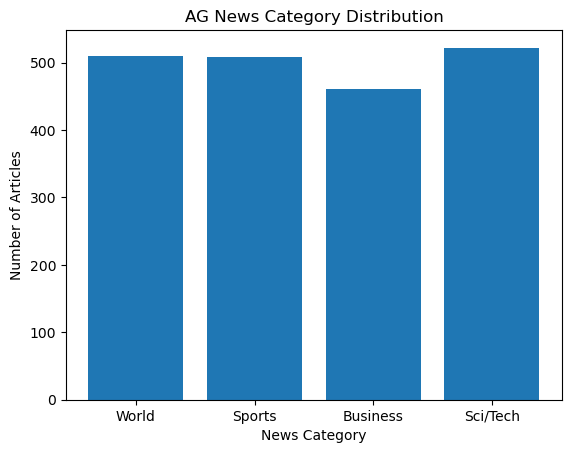

In [22]:
import matplotlib.pyplot as plt

labels = ["World", "Sports", "Business", "Sci/Tech"]

counts = [
    train_dataset["labels"].count(0) if "labels" in train_dataset.column_names
    else train_dataset["label"].count(0),
    train_dataset["labels"].count(1) if "labels" in train_dataset.column_names
    else train_dataset["label"].count(1),
    train_dataset["labels"].count(2) if "labels" in train_dataset.column_names
    else train_dataset["label"].count(2),
    train_dataset["labels"].count(3) if "labels" in train_dataset.column_names
    else train_dataset["label"].count(3)
]

plt.bar(labels, counts)

plt.xlabel("News Category")
plt.ylabel("Number of Articles")
plt.title("AG News Category Distribution")

plt.show()